In [12]:
#Import Statements
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    log_loss
)

RANDOM_STATE = 42
TEST_FRACTION = 0.15
GAP = 1

RETRAIN_SCHEDULES = {
    "Daily": 1,
    "Weekly": 5,
    "Monthly": 21,
    "Quarterly": 63
}

pd.set_option("display.max_columns", None)

In [13]:
#Load AAPL dataset
DATA_PATH = Path("../data/raw/AAPL_daily_raw.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("data/raw/AAPL_daily_raw.csv")

df = pd.read_csv(DATA_PATH, index_col=0)

# Preserve original trading dates while removing timezone suffixes.
df.index = pd.to_datetime(
    df.index.astype(str).str.slice(0, 19),
    errors="raise"
)

df = df.sort_index()
df.index.name = "Date"

print("Rows:", len(df))
print("Date range:", df.index.min(), "to", df.index.max())

df.head()

Rows: 2766
Date range: 2015-01-02 00:00:00 to 2025-12-31 00:00:00


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,daily_return
Date,,,,,,,,,
2015-01-02,27.847500,27.860001,26.837500,27.332500,24.171755,212818400,0.0,0.0,NaN
2015-01-05,27.072500,27.162500,26.352501,26.562500,23.490799,257142000,0.0,0.0,-0.028172
2015-01-06,26.635000,26.857500,26.157499,26.565001,23.493013,263188400,0.0,0.0,0.000094
2015-01-07,26.799999,27.049999,26.674999,26.937500,23.822430,160423600,0.0,0.0,0.014022
2015-01-08,27.307501,28.037500,27.174999,27.972500,24.737757,237458000,0.0,0.0,0.038423


In [14]:
#Build features for the model
FEATURES = [
    "return_1d",
    "return_5d",
    "return_10d",
    "price_to_sma20",
    "price_to_sma50",
    "volatility_20d",
    "momentum_10d",
    "relative_volume"
]

df["return_1d"] = df["Adj Close"].pct_change(1)
df["return_5d"] = df["Adj Close"].pct_change(5)
df["return_10d"] = df["Adj Close"].pct_change(10)

df["sma20"] = df["Adj Close"].rolling(20).mean()
df["sma50"] = df["Adj Close"].rolling(50).mean()

df["price_to_sma20"] = df["Adj Close"] / df["sma20"] - 1
df["price_to_sma50"] = df["Adj Close"] / df["sma50"] - 1

df["volatility_20d"] = df["return_1d"].rolling(20).std()
df["momentum_10d"] = df["Adj Close"].pct_change(10)

df["relative_volume"] = (
    df["Volume"] / df["Volume"].rolling(20).mean()
)

df["future_return_1d"] = (
    df["Adj Close"].shift(-1) / df["Adj Close"] - 1
)

df["target_up"] = (
    df["future_return_1d"] > 0
).astype(int)

model_df = df[
    FEATURES + ["future_return_1d", "target_up"]
].dropna().copy()

model_df = model_df.dropna(subset=["future_return_1d"])

X = model_df[FEATURES]
y = model_df["target_up"]

print("Rows:", len(model_df))
print("Features:", len(FEATURES))
print("\nTarget distribution:")
print(y.value_counts(normalize=True).rename("proportion"))

Rows: 2716
Features: 8

Target distribution:
target_up
1    0.529455
0    0.470545
Name: proportion, dtype: float64


In [19]:
#Train-test split

n = len(model_df)
development_end = int(n * (1 - TEST_FRACTION))

X_development = X.iloc[:development_end]
y_development = y.iloc[:development_end]

X_test = X.iloc[development_end:]
y_test = y.iloc[development_end:]

print("Development rows:", len(X_development))
print("Test rows:", len(X_test))

print(
    "Development dates:",
    X_development.index.min(),
    "to",
    X_development.index.max()
)

print(
    "Test dates:",
    X_test.index.min(),
    "to",
    X_test.index.max()
)

Development rows: 2308
Test rows: 408
Development dates: 2015-03-16 00:00:00 to 2024-05-14 00:00:00
Test dates: 2024-05-15 00:00:00 to 2025-12-30 00:00:00


In [21]:
#Define the model
base_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=0.1,
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

In [22]:
# Walk-forward validation function
def run_walk_forward(
    X,
    y,
    X_test,
    base_model,
    retrain_every,
    gap=1
):
    prediction_records = []

    test_start_position = len(X) - len(X_test)

    for block_number, block_start in enumerate(
        range(0, len(X_test), retrain_every),
        start=1
    ):

        block_end = min(
            block_start + retrain_every,
            len(X_test)
        )

        # Full-dataset position of the first row in this block.
        absolute_start = test_start_position + block_start

        # Exclude the gap immediately before prediction begins.
        train_end = absolute_start - gap

        X_train = X.iloc[:train_end]
        y_train = y.iloc[:train_end]

        X_block = X_test.iloc[block_start:block_end]
        y_block = y.loc[X_block.index]

        fitted_model = clone(base_model)
        fitted_model.fit(X_train, y_train)

        predictions = fitted_model.predict(X_block)
        probabilities = fitted_model.predict_proba(X_block)[:, 1]

        for i, prediction_date in enumerate(X_block.index):
            prediction_records.append({
                "date": prediction_date,
                "block": block_number,
                "training_rows": len(X_train),
                "training_end": X_train.index[-1],
                "prediction": int(predictions[i]),
                "probability_up": float(probabilities[i]),
                "actual": int(y_block.iloc[i])
            })

    return pd.DataFrame(prediction_records)

In [23]:
#Run walk-forward validation for each retraining schedule
schedule_predictions = {}

for schedule_name, interval in RETRAIN_SCHEDULES.items():

    print(f"Running {schedule_name} schedule...")

    predictions_df = run_walk_forward(
        X=X,
        y=y,
        X_test=X_test,
        base_model=base_model,
        retrain_every=interval,
        gap=GAP
    )

    schedule_predictions[schedule_name] = predictions_df

print("\nAll schedules completed.")

Running Daily schedule...
Running Weekly schedule...
Running Monthly schedule...
Running Quarterly schedule...

All schedules completed.


In [25]:
#Verify prediction coverage
for schedule_name, predictions_df in schedule_predictions.items():

    assert len(predictions_df) == len(X_test)

    assert predictions_df["date"].is_unique

    assert predictions_df["date"].tolist() == (
        X_test.index.tolist()
    )

    print(
        schedule_name,
        "| Predictions:", len(predictions_df),
        "| Unique dates:", predictions_df["date"].nunique()
    )

print("\nAll schedules cover the test period exactly once.")

Daily | Predictions: 408 | Unique dates: 408
Weekly | Predictions: 408 | Unique dates: 408
Monthly | Predictions: 408 | Unique dates: 408
Quarterly | Predictions: 408 | Unique dates: 408

All schedules cover the test period exactly once.


In [26]:
#Check training cut offs
for schedule_name, predictions_df in schedule_predictions.items():

    # Training must finish before the prediction date.
    assert (
        predictions_df["training_end"]
        < predictions_df["date"]
    ).all()

    print(
        schedule_name,
        "| Latest training date:",
        predictions_df["training_end"].max()
    )

Daily | Latest training date: 2025-12-26 00:00:00
Weekly | Latest training date: 2025-12-23 00:00:00
Monthly | Latest training date: 2025-12-15 00:00:00
Quarterly | Latest training date: 2025-11-13 00:00:00


In [27]:
#Create the performance metrics for each retraining schedule
def calculate_metrics(predictions_df):

    return {
        "balanced_accuracy": balanced_accuracy_score(
            predictions_df["actual"],
            predictions_df["prediction"]
        ),
        "macro_f1": f1_score(
            predictions_df["actual"],
            predictions_df["prediction"],
            average="macro",
            zero_division=0
        ),
        "log_loss": log_loss(
            predictions_df["actual"],
            predictions_df["probability_up"],
            labels=[0, 1]
        )
    }


summary_rows = []

for schedule_name, predictions_df in schedule_predictions.items():

    metrics = calculate_metrics(predictions_df)

    summary_rows.append({
        "schedule": schedule_name,
        "retrain_every": RETRAIN_SCHEDULES[schedule_name],
        "retraining_events": predictions_df["block"].nunique(),
        **metrics
    })

schedule_summary = pd.DataFrame(summary_rows)

display(
    schedule_summary.sort_values(
        "retrain_every"
    ).round(4)
)

,schedule,retrain_every,retraining_events,balanced_accuracy,macro_f1,log_loss
0,Daily,1,408,0.4658,0.4655,0.6981
1,Weekly,5,82,0.4679,0.4677,0.6981
2,Monthly,21,20,0.4708,0.4704,0.6977
3,Quarterly,63,7,0.4729,0.4726,0.6982


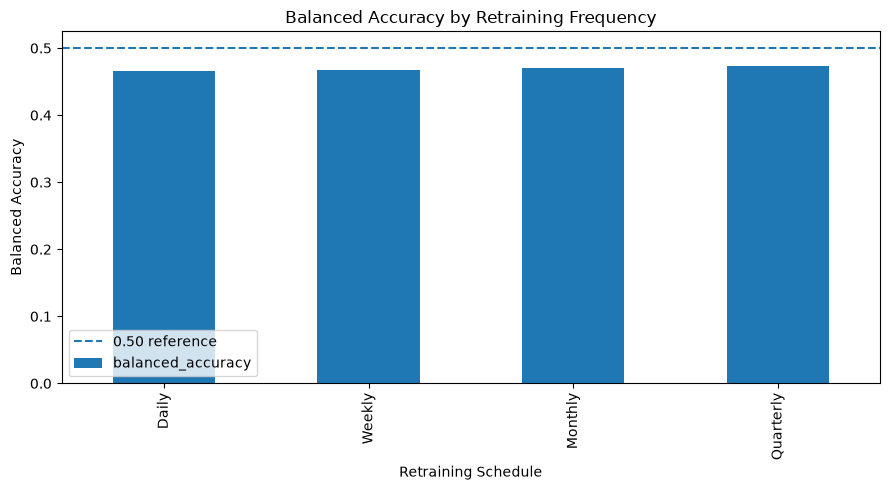

In [28]:
#Plot the balanced accuracy for each retraining schedule
schedule_summary.plot(
    x="schedule",
    y="balanced_accuracy",
    kind="bar",
    figsize=(9, 5),
    legend=False,
    title="Balanced Accuracy by Retraining Frequency"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="0.50 reference"
)

plt.ylabel("Balanced Accuracy")
plt.xlabel("Retraining Schedule")
plt.legend()
plt.tight_layout()
plt.show()

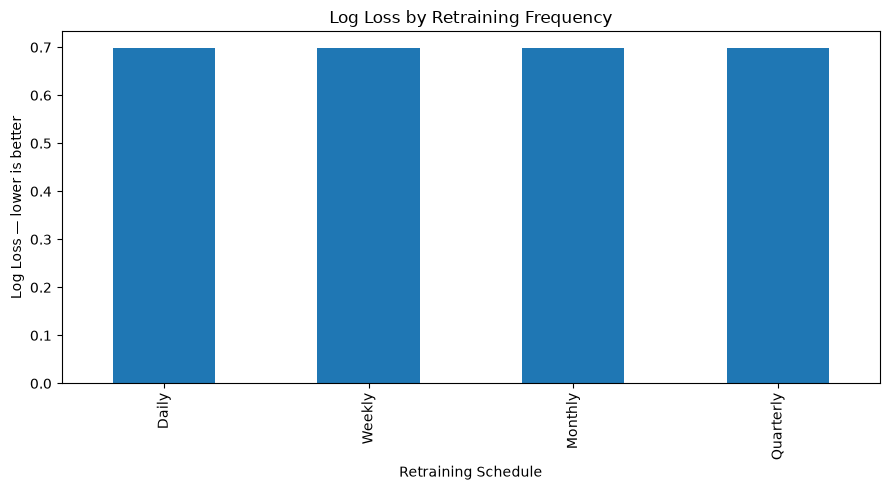

In [29]:
#Plot the log loss for each retraining schedule
schedule_summary.plot(
    x="schedule",
    y="log_loss",
    kind="bar",
    figsize=(9, 5),
    legend=False,
    title="Log Loss by Retraining Frequency"
)

plt.ylabel("Log Loss — lower is better")
plt.xlabel("Retraining Schedule")
plt.tight_layout()
plt.show()

In [31]:
#Building the monthly ledger
monthly_ledger = schedule_predictions["Monthly"].copy()

monthly_ledger["actual_direction"] = (
    monthly_ledger["actual"]
    .map({0: "DOWN", 1: "UP"})
)

monthly_ledger["predicted_direction"] = (
    monthly_ledger["prediction"]
    .map({0: "DOWN", 1: "UP"})
)

monthly_ledger["correct"] = (
    monthly_ledger["actual"]
    == monthly_ledger["prediction"]
)

monthly_ledger["confidence"] = np.maximum(
    monthly_ledger["probability_up"],
    1 - monthly_ledger["probability_up"]
)

monthly_ledger = monthly_ledger[
    [
        "date",
        "block",
        "training_rows",
        "training_end",
        "predicted_direction",
        "probability_up",
        "confidence",
        "actual_direction",
        "correct"
    ]
]

display(monthly_ledger.head(15))

,date,block,training_rows,training_end,predicted_direction,probability_up,confidence,actual_direction,correct
0,2024-05-15,1,2307,2024-05-13,UP,0.501614,0.501614,UP,True
1,2024-05-16,1,2307,2024-05-13,UP,0.518053,0.518053,UP,True
2,2024-05-17,1,2307,2024-05-13,UP,0.517412,0.517412,UP,True
3,2024-05-20,1,2307,2024-05-13,UP,0.507757,0.507757,UP,True
4,2024-05-21,1,2307,2024-05-13,UP,0.505958,0.505958,DOWN,False
5,2024-05-22,1,2307,2024-05-13,UP,0.522664,0.522664,DOWN,False
6,2024-05-23,1,2307,2024-05-13,UP,0.531330,0.531330,UP,True
7,2024-05-24,1,2307,2024-05-13,DOWN,0.483159,0.516841,UP,False
8,2024-05-28,1,2307,2024-05-13,UP,0.502200,0.502200,UP,True
9,2024-05-29,1,2307,2024-05-13,DOWN,0.498524,0.501476,UP,False


In [32]:
#Inspect incorrect and confident predictions
incorrect_predictions = monthly_ledger[
    monthly_ledger["correct"] == False
].sort_values(
    "confidence",
    ascending=False
)

display(incorrect_predictions.head(10))

,date,block,training_rows,training_end,predicted_direction,probability_up,confidence,actual_direction,correct
18,2024-06-11,1,2307,2024-05-13,DOWN,0.391392,0.608608,UP,False
221,2025-04-03,11,2517,2025-03-17,UP,0.577734,0.577734,DOWN,False
306,2025-08-06,15,2601,2025-07-17,DOWN,0.429622,0.570378,UP,False
227,2025-04-11,11,2517,2025-03-17,DOWN,0.432071,0.567929,UP,False
247,2025-05-12,12,2538,2025-04-15,DOWN,0.435090,0.564910,UP,False
174,2025-01-27,9,2475,2025-01-14,DOWN,0.439920,0.560080,UP,False
337,2025-09-19,17,2643,2025-09-16,DOWN,0.444631,0.555369,UP,False
152,2024-12-20,8,2454,2024-12-11,DOWN,0.446087,0.553913,UP,False
358,2025-10-20,18,2664,2025-10-15,DOWN,0.446343,0.553657,UP,False
175,2025-01-28,9,2475,2025-01-14,DOWN,0.448177,0.551823,UP,False


In [33]:
#Summarize the monthly ledger
print("Total predictions:", len(monthly_ledger))

print(
    "Correct predictions:",
    monthly_ledger["correct"].sum()
)

print(
    "Accuracy:",
    monthly_ledger["correct"].mean().round(4)
)

print(
    "Average confidence:",
    monthly_ledger["confidence"].mean().round(4)
)

print("\nPredicted direction counts:")
print(monthly_ledger["predicted_direction"].value_counts())

print("\nActual direction counts:")
print(monthly_ledger["actual_direction"].value_counts())

Total predictions: 408
Correct predictions: 194
Accuracy: 0.4755
Average confidence: 0.5148

Predicted direction counts:
predicted_direction
UP      217
DOWN    191
Name: count, dtype: int64

Actual direction counts:
actual_direction
UP      231
DOWN    177
Name: count, dtype: int64


In [34]:
#Save the monthly ledger
OUTPUT_DIR = Path("../data/processed")

if not OUTPUT_DIR.exists():
    OUTPUT_DIR = Path("data/processed")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = OUTPUT_DIR / "AAPL_walk_forward_monthly_predictions.csv"

monthly_ledger.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Saved:", OUTPUT_PATH)

Saved: data\processed\AAPL_walk_forward_monthly_predictions.csv


In [35]:
#Reading the saved ledger to verify it was written correctly
loaded_ledger = pd.read_csv(
    OUTPUT_PATH,
    parse_dates=["date", "training_end"]
)

assert len(loaded_ledger) == len(monthly_ledger)
assert loaded_ledger["date"].is_unique

print("Saved ledger successfully reloaded.")
display(loaded_ledger.head())

Saved ledger successfully reloaded.


,date,block,training_rows,training_end,predicted_direction,probability_up,confidence,actual_direction,correct
0,2024-05-15,1,2307,2024-05-13,UP,0.501614,0.501614,UP,True
1,2024-05-16,1,2307,2024-05-13,UP,0.518053,0.518053,UP,True
2,2024-05-17,1,2307,2024-05-13,UP,0.517412,0.517412,UP,True
3,2024-05-20,1,2307,2024-05-13,UP,0.507757,0.507757,UP,True
4,2024-05-21,1,2307,2024-05-13,UP,0.505958,0.505958,DOWN,False


In [ ]:
#End of this notebook